In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec
from scipy import stats
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites

## Parameters

In [2]:
n3     = [-5,  5, 210, 270]
n34    = [-5,  5, 190, 240]
regbox = [-40, 40,  120, 300]

timesfut = ["2070-01", "2100-01"]
timespi  = ["1850-01", "1880-01"]

var_names = [
    "Qp", "ekU", "ekV", "eddyU", "eddyV",
    "UmdTpdx", "VmdTpdy", "upwelling", "eddyvert",
    "thermocline", "dTpdt"
]

# SON window in the composite (months relative to DJF peak)
SON_M1 = -4
SON_M2 = -1

# Terms to show in summary figure
plot_terms = ['ekU_total', 'ekV_total', 'eddyV', 'thermocline', 'dTpdt']

term_labels = {
    'ekU_total':   'ekU',
    'ekV_total':   'ekV',
    'eddyV':       'eddyV',
    'thermocline': 'Thermocline',
    'dTpdt':       'dTp/dt',
}

## Load data

In [3]:
# Heat budget terms
ds_hb_hist = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/hist_corrQ_hb_terms.nc")
ds_hb_fut  = xr.open_dataset("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/hb_analysis/fut_corrQ_hb_terms.nc")

lat = ds_hb_fut['lat']
lon = ds_hb_fut['lon']

vars_hist = {var: ds_hb_hist[var] for var in var_names}
vars_fut  = {var: ds_hb_fut[var]  for var in var_names}

# SST for event identification
dssst = xr.open_dataset("/glade/work/smagahey/UCSB/codes/generated_files/tos_1850_2100_E3SMv1LE.nc")
tos   = dssst['tos'] - dssst['tos'].mean('member')

# Year arrays for var_composites
yrshist = xr.DataArray(np.arange(1850, 1880).astype(str), dims='time')
yrsfut  = xr.DataArray(np.arange(2070, 2100).astype(str), dims='time')

## Identify EN/LN events

In [4]:
enyrs_pi, lnyrs_pi = select_events(tos, n34, regbox, 1850, 1880, timespi)
enyrs_fu, lnyrs_fu = select_events(tos, n34, regbox, 2070, 2100, timesfut)

# Limit to 14 members to match heat budget data
enyrs_pi = enyrs_pi.isel(member=slice(0, 14))
lnyrs_pi = lnyrs_pi.isel(member=slice(0, 14))
enyrs_fu = enyrs_fu.isel(member=slice(0, 14))
lnyrs_fu = lnyrs_fu.isel(member=slice(0, 14))

print(f'PI  EN events: {int(np.sum(~np.isnan(enyrs_pi.values.astype(float))))}  '
      f'LN events: {int(np.sum(~np.isnan(lnyrs_pi.values.astype(float))))}')
print(f'FUT EN events: {int(np.sum(~np.isnan(enyrs_fu.values.astype(float))))}  '
      f'LN events: {int(np.sum(~np.isnan(lnyrs_fu.values.astype(float))))}')

PI  EN events: 110  LN events: 135
FUT EN events: 115  LN events: 120


## Composite SON heat budget terms

For each term, composite over EN and LN events using `var_composites`,
then average over the SON window (months -4 to -1 relative to DJF peak).

In [5]:
def composite_son(var_data, yrs_event, yrs_range, enyrs, lnyrs, m1, m2):
    """
    Composite a heat budget term over EN and LN event years,
    averaged over the SON window (months m1 to m2).

    Returns
    -------
    en_comp, ln_comp : (lat, lon) spatial maps
    """
    comp_en, comp_ln = var_composites(var_data, yrs_range, enyrs, lnyrs, 24)
    en_son = comp_en.sel(time=slice(m1, m2)).mean('time').mean('member')
    ln_son = comp_ln.sel(time=slice(m1, m2)).mean('time').mean('member')
    return en_son, ln_son


# Storage: comps[period][term] = (en_map, ln_map)
comps = {'pi': {}, 'fut': {}}

for term in var_names:
    print(f'Compositing {term}...')

    en_pi, ln_pi = composite_son(
        vars_hist[term].isel(member=slice(0, 14)),
        yrshist, yrshist, enyrs_pi, lnyrs_pi, SON_M1, SON_M2
    )
    en_fu, ln_fu = composite_son(
        vars_fut[term].isel(member=slice(0, 14)),
        yrsfut, yrsfut, enyrs_fu, lnyrs_fu, SON_M1, SON_M2
    )

    comps['pi'][term]  = (en_pi,  ln_pi)
    comps['fut'][term] = (en_fu,  ln_fu)

# Combine ekU+UmdTpdx and ekV+VmdTpdy
for period in ['pi', 'fut']:
    en_u = comps[period]['ekU'][0] #+ comps[period]['UmdTpdx'][0]
    ln_u = comps[period]['ekU'][1] #+ comps[period]['UmdTpdx'][1]
    en_v = comps[period]['ekV'][0] #+ comps[period]['VmdTpdy'][0]
    ln_v = comps[period]['ekV'][1] #+ comps[period]['VmdTpdy'][1]
    comps[period]['ekU_total'] = (en_u, ln_u)
    comps[period]['ekV_total'] = (en_v, ln_v)

print('Done.')

Compositing Qp...
Compositing ekU...
Compositing ekV...
Compositing eddyU...
Compositing eddyV...
Compositing UmdTpdx...
Compositing VmdTpdy...
Compositing upwelling...
Compositing eddyvert...
Compositing thermocline...
Compositing dTpdt...
Done.


## Plot: SON heat budget composites prior to EN and LN

Layout: rows = terms, columns = PI EN | PI LN | FUT EN | FUT LN

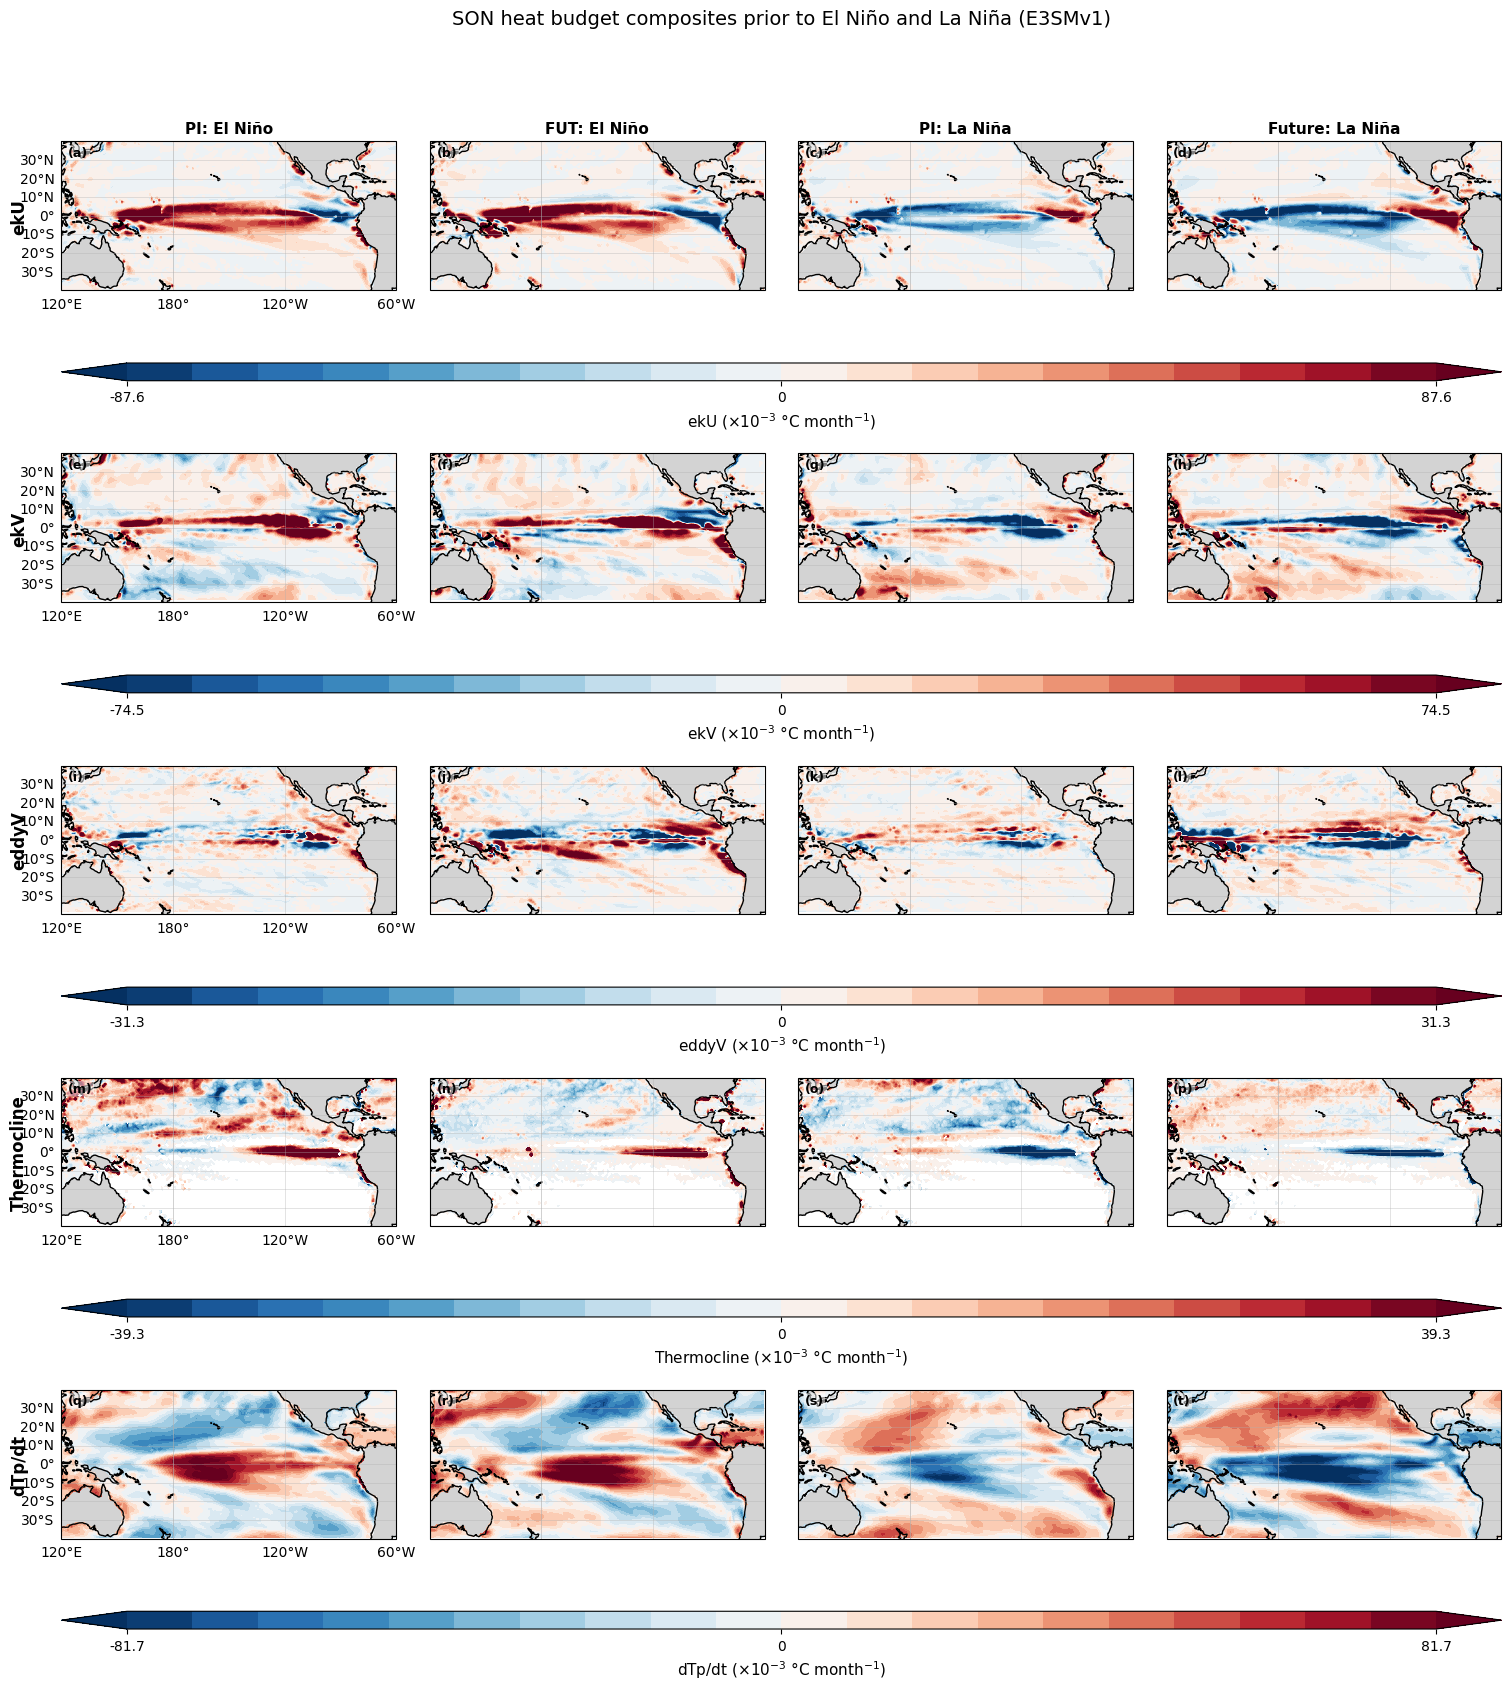

In [6]:
n_terms = len(plot_terms)
fig = plt.figure(figsize=(18, 4 * n_terms))

gs = GridSpec(n_terms * 2, 4, figure=fig,
              hspace=0.15, wspace=0.1,
              height_ratios=[1, 0.07] * n_terms)

col_titles = ['PI: El Niño', 'FUT: El Niño', 'PI: La Niña', 'Future: La Niña']
lon2d, lat2d = np.meshgrid(lon, lat)

for row, term in enumerate(plot_terms):
    maps = [
        comps['pi'][term][0],   # PI EN
        comps['fut'][term][0],   # PI LN
        comps['pi'][term][1],  # FUT EN
        comps['fut'][term][1],  # FUT LN
    ]

    # Symmetric colorbar across all 4 panels for this term
    vmax = max(float(np.nanpercentile(np.abs(m.values), 95)) for m in maps)
    if vmax == 0 or np.isnan(vmax):
        vmax = 1.0

    map_axes = []
    for col, data_map in enumerate(maps):
        ax = fig.add_subplot(gs[row * 2, col],
                             projection=ccrs.PlateCarree(central_longitude=180))
        map_axes.append(ax)

        im = ax.contourf(
            lon, lat, data_map.values,
            levels=np.linspace(-vmax, vmax, 21),
            cmap='RdBu_r', extend='both',
            transform=ccrs.PlateCarree()
        )

        ax.coastlines()
        ax.add_feature(cfeature.LAND, facecolor='lightgray')
        ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
        gl = ax.gridlines(draw_labels=(col == 0), linewidth=0.5, alpha=0.5)
        gl.top_labels   = False
        gl.right_labels = False

        if row == 0:
            ax.set_title(col_titles[col], fontsize=11, fontweight='bold')

        # Panel labels
        label = chr(97 + row * 4 + col)  # a, b, c, d, e, f...
        ax.text(0.02, 0.97, f'({label})', transform=ax.transAxes,
                fontsize=9, fontweight='bold', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

    # Row label
    map_axes[0].text(-0.1, 0.5, term_labels.get(term, term),
                     va='center', ha='right', rotation=90,
                     fontsize=12, fontweight='bold',
                     transform=map_axes[0].transAxes)

    # Colorbar
    cbar_ax = fig.add_subplot(gs[row * 2 + 1, :])
    cb = fig.colorbar(im, cax=cbar_ax, orientation='horizontal', extend='both')
    cb.set_ticks([-vmax, 0, vmax])
    cb.set_ticklabels([f'{-vmax*1e3:.1f}', '0', f'{vmax*1e3:.1f}'])
    cb.set_label(f'{term_labels.get(term, term)} (×10$^{{-3}}$ °C month$^{{-1}}$)', fontsize=11)

fig.subplots_adjust(left=0.1)
fig.suptitle('SON heat budget composites prior to El Niño and La Niña (E3SMv1)', fontsize=14, y=0.92)
plt.savefig('hb_composites_son_en_ln.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
import string

def plot_multiterm_summary_composite(terms, results_pi, results_fut, lats, lons, lag='MAM'):
    term_labels = {
        'ekU_total':   'ekU',
        'ekV_total':   'ekV',
        'eddyV':       'eddyV',
        'thermocline': 'Thermocline',
        'dTpdt':       'dTp/dt',
    }
    n_terms = len(terms)
    fig = plt.figure(figsize=(16, 4 * n_terms))
    from matplotlib.gridspec import GridSpec
    gs = GridSpec(n_terms, 3, figure=fig,
                  hspace=0.35, wspace=0.1,
                  width_ratios=[1, 1, 0.04])

    panel_labels = iter(string.ascii_lowercase)  # a, b, c, ...

    for row, term in enumerate(terms):
        data_pi  = results_pi[term][lag]
        data_fut = results_fut[term][lag]
        vmax = max(np.nanpercentile(np.abs(d[0]), 95) for d in [data_pi, data_fut])
        if vmax == 0 or np.isnan(vmax):
            vmax = 1.0
        map_axes = []
        for col, (reg_map, corr_map, p_map) in enumerate([data_pi, data_fut]):
            ax = fig.add_subplot(gs[row, col],                 # <-- just "row", not "row*2"
                                 projection=ccrs.PlateCarree(central_longitude=180))
            map_axes.append(ax)
            im = ax.contourf(
                lons, lats, reg_map,
                levels=np.linspace(-vmax, vmax, 21),
                cmap='RdBu_r', extend='both',
                transform=ccrs.PlateCarree()
            )
            lon2d, lat2d = np.meshgrid(lons, lats)
            sig_mask = p_map[::3, ::3] < 0.05
            ax.scatter(lon2d[::3, ::3][sig_mask], lat2d[::3, ::3][sig_mask],
                       c='k', s=0.5, transform=ccrs.PlateCarree())
            ax.coastlines()
            ax.add_feature(cfeature.LAND, facecolor='lightgray')
            ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
            #gl = ax.gridlines(draw_labels=(col == 0), linewidth=0.5, alpha=0.5)
            #gl = ax.gridlines(draw_labels=(row == n_terms - 1), linewidth=0.5, alpha=0.5)
            #gl.top_labels   = False
            #gl.right_labels = False
            gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
            gl.top_labels    = False
            gl.right_labels  = False
            gl.bottom_labels = (row == n_terms - 1)   # lon labels only on bottom row (i, j)
            gl.left_labels   = (col == 0)
            if row == 0:
                title = f'PI: {lag} NPMM -> SON' if col == 0 else f'Future: {lag} NPMM -> SON'
                ax.set_title(title, fontsize=20, fontweight='bold')

            # a-k panel label, top-left corner
            label = next(panel_labels)
            ax.text(0.02, 0.95, f'({label})', transform=ax.transAxes,
                     fontsize=16, fontweight='bold', va='top', ha='left',
                     bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1.5))

        #map_axes[0].text(-0.1, 0.5, term_labels.get(term, term),
         #                va='center', ha='right', rotation=90, fontsize=20, fontweight='bold',
         #                transform=map_axes[0].transAxes)
       
        #cbar_ax = fig.add_subplot(gs[row * 2 + 1, :])

        map_axes[0].text(-0.1, 0.5, term_labels.get(term, term),
                 va='center', ha='right', rotation=90, fontsize=20, fontweight='bold',
                 transform=map_axes[0].transAxes)

        cbar_ax = fig.add_subplot(gs[row, 2])                   # <-- "row", col index 2
        cb = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='both')
        #cb = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='both')
        cb.set_ticks([-vmax, 0, vmax])
        cb.set_ticklabels([f'{-vmax*1e3:.1f}', '0', f'{vmax*1e3:.1f}'])
        cb.set_label(f'{term_labels.get(term, term)} (×10$^{{-3}}$ °C month$^{{-1}}$)', fontsize=14)


    fig.subplots_adjust(left=0.12)
    fig.suptitle('SON heat budget regression onto NPMM', fontsize=20, y=.92)
    #plt.savefig('composite_npmm_hb_summary_SON.png', dpi=150, bbox_inches='tight')
    plt.show()

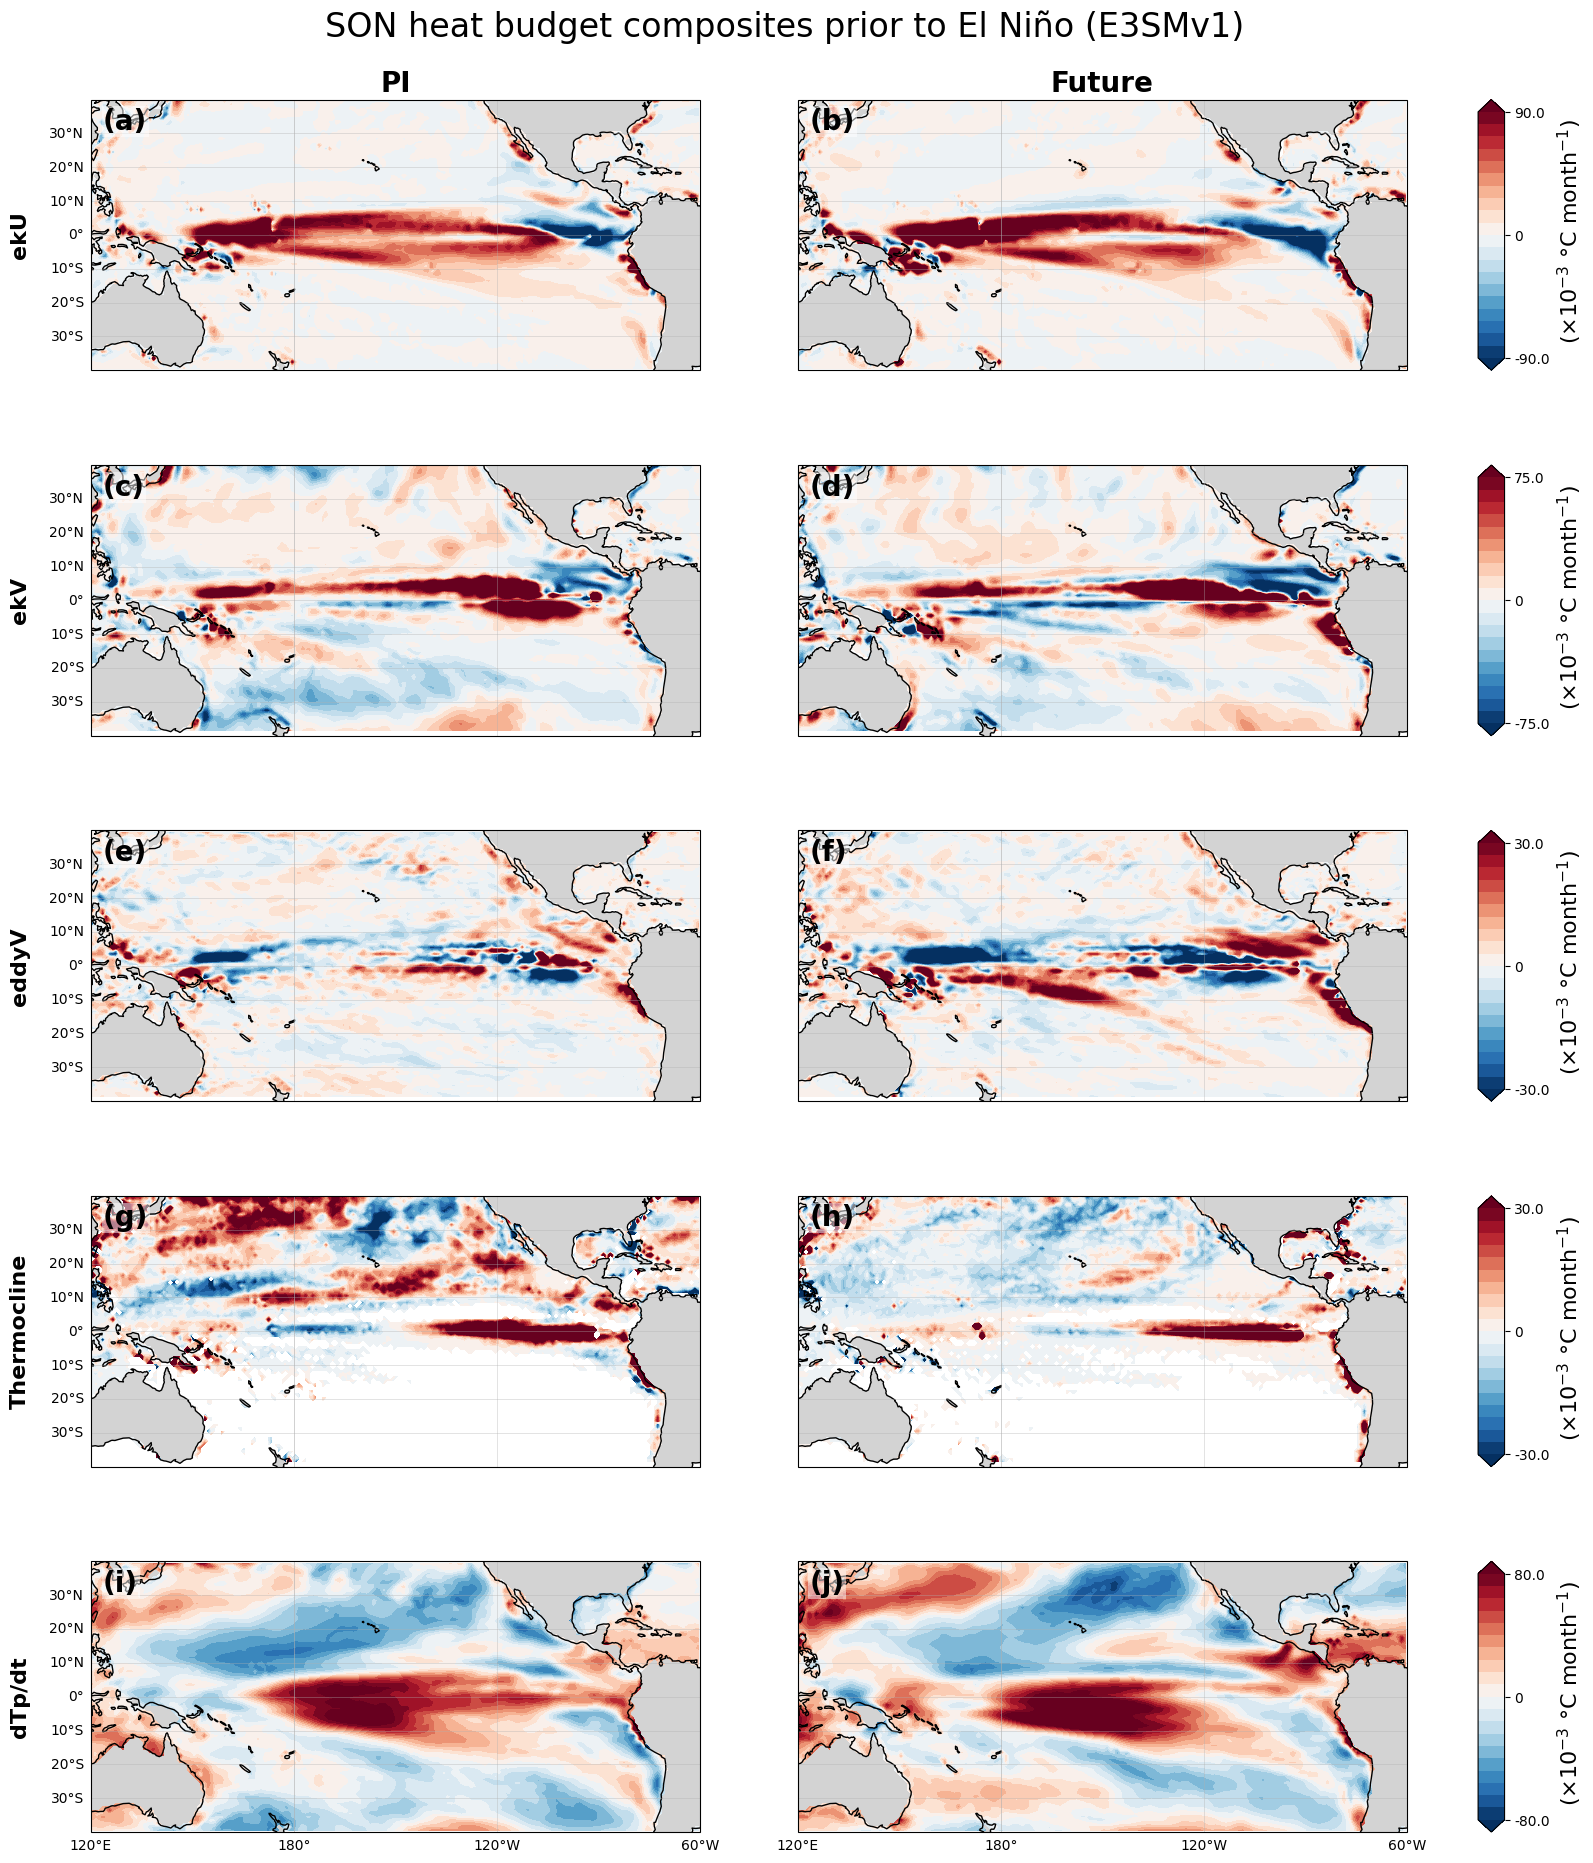

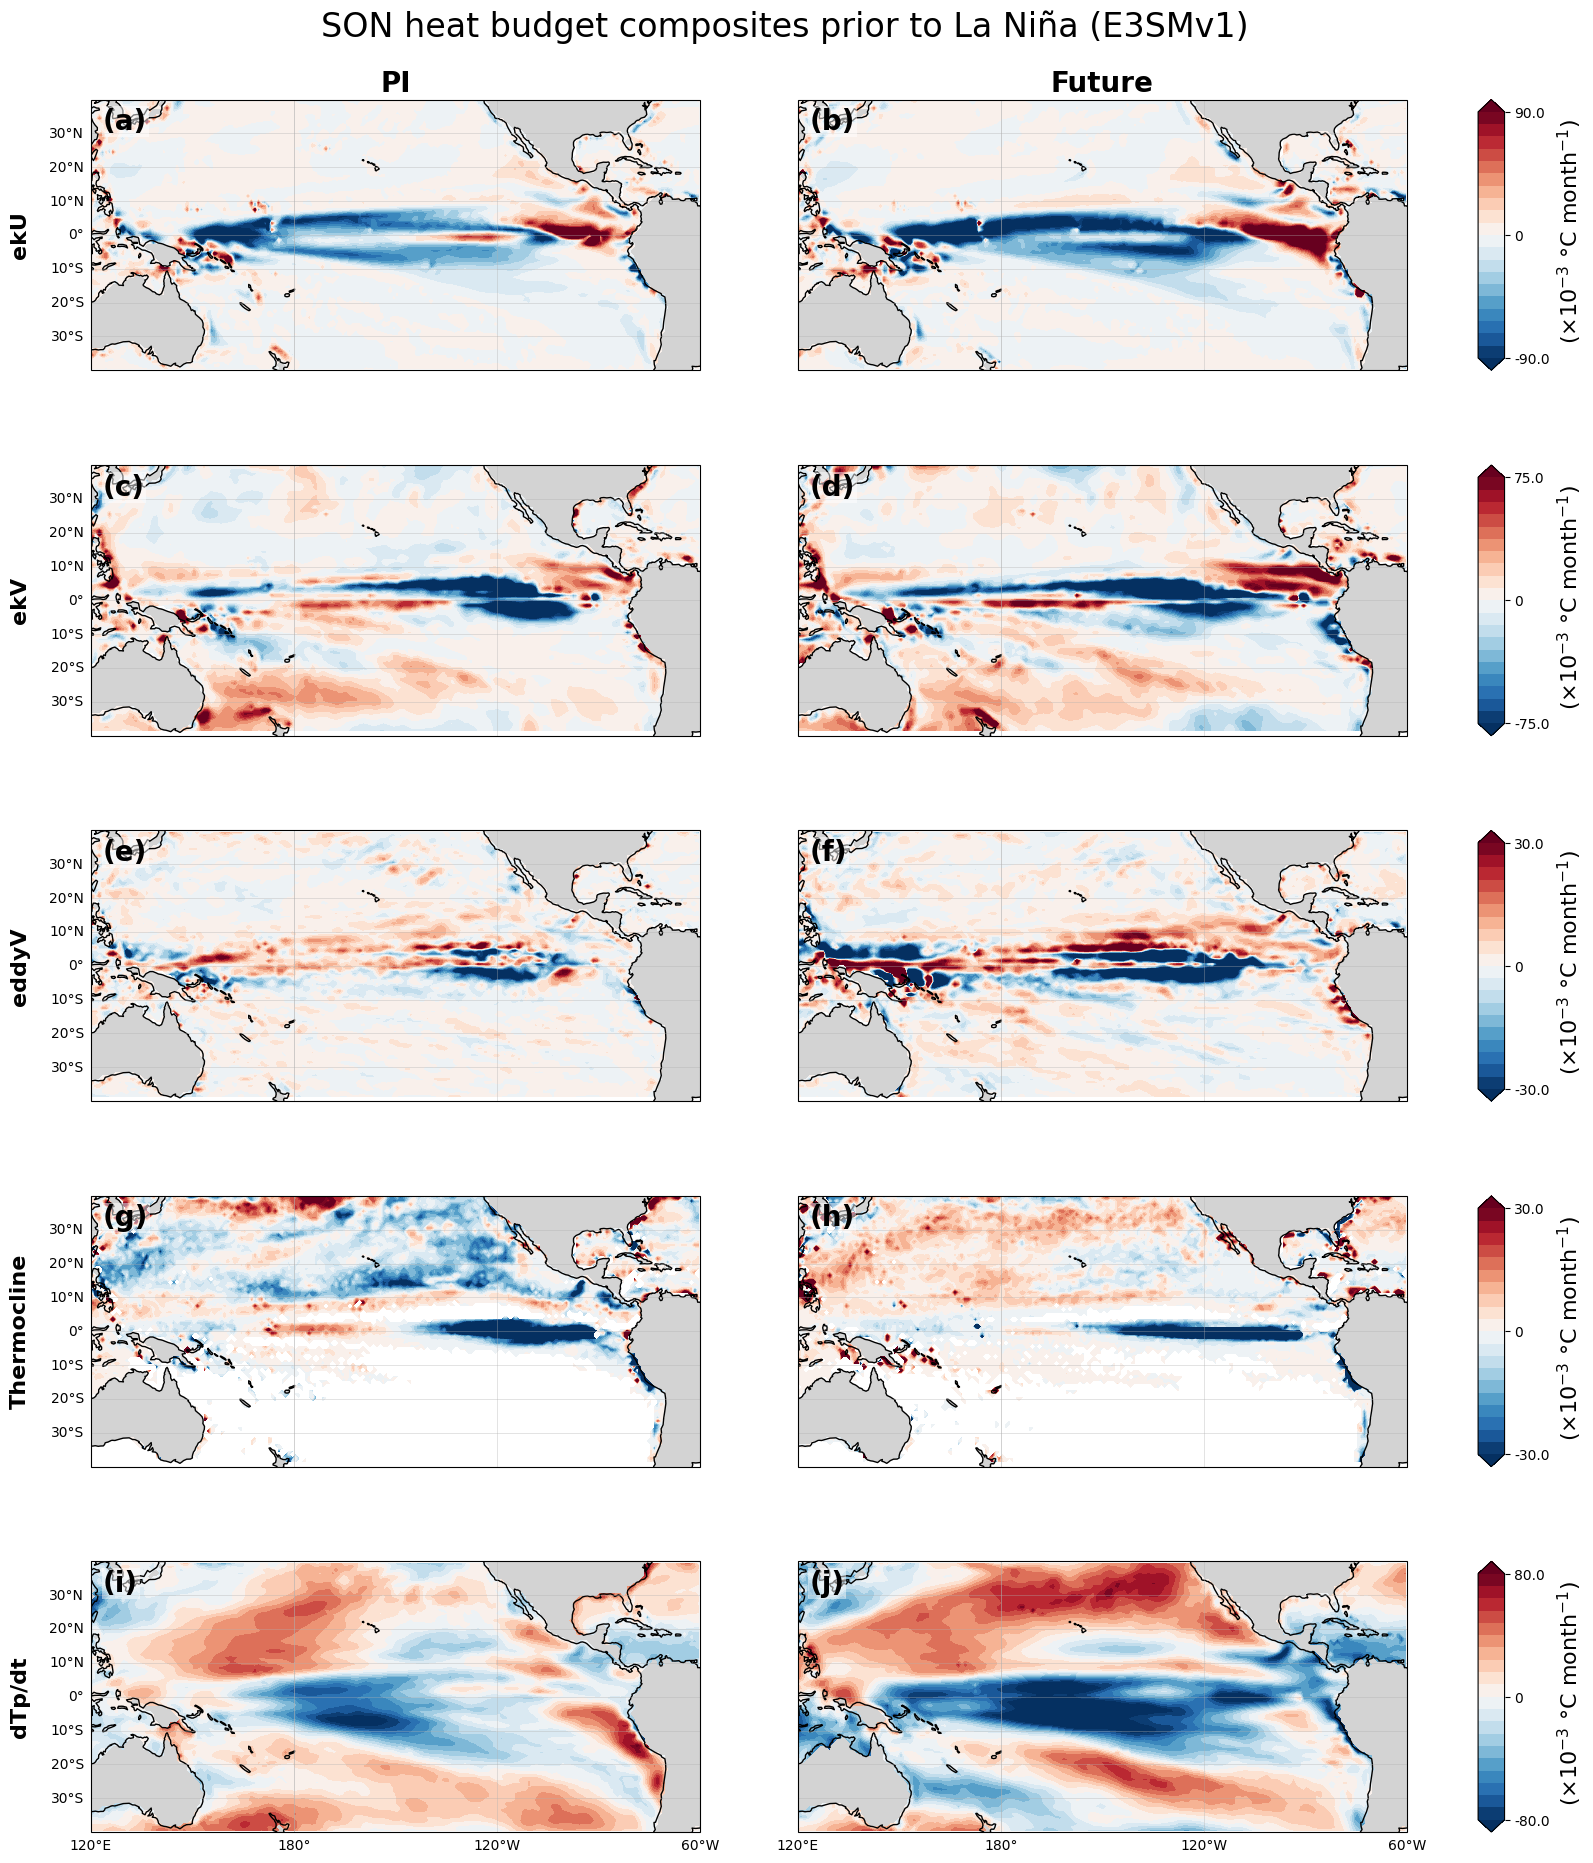

In [18]:
def plot_hb_composite(comps, event, plot_terms, term_labels, lat, lon, lag_label='SON'):
    idx   = 0 if event == 'en' else 1
    titles = ['PI', 'Future']
    n_terms = len(plot_terms)
    
    vmaxes = [90e-3, 75e-3, 30e-3, 30e-3, 80e-3]  # ← add here
    
    fig = plt.figure(figsize=(18, 4.5 * n_terms))
    from matplotlib.gridspec import GridSpec
    gs = GridSpec(n_terms, 3, figure=fig,
                  hspace=0.35, wspace=0.1,
                  width_ratios=[1, 1, 0.04])

    for row, term in enumerate(plot_terms):
        maps = [comps['pi'][term][idx], comps['fut'][term][idx]]

        vmax = vmaxes[row]

        map_axes = []
        for col, data_map in enumerate(maps):
            ax = fig.add_subplot(gs[row, col],
                                 projection=ccrs.PlateCarree(central_longitude=180))
            map_axes.append(ax)

            im = ax.contourf(lon, lat, data_map.values,levels=np.linspace(-vmax, vmax, 21),cmap='RdBu_r', extend='both',transform=ccrs.PlateCarree())
            ax.coastlines()
            ax.add_feature(cfeature.LAND, facecolor='lightgray')
            ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
            gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
            gl.top_labels    = False
            gl.right_labels  = False
            gl.bottom_labels = (row == n_terms - 1)   # lon labels only on bottom row (i, j)
            gl.left_labels   = (col == 0)

            if row == 0:
                ax.set_title(titles[col], fontsize=20, fontweight='bold')

            label = chr(97 + row * 2 + col)
            ax.text(0.02, 0.97, f'({label})', transform=ax.transAxes,fontsize=20, fontweight='bold', va='top', ha='left',bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))

        map_axes[0].text(-0.1, 0.5, term_labels.get(term, term),va='center', ha='right', rotation=90,fontsize=16, fontweight='bold',transform=map_axes[0].transAxes)

        cbar_ax = fig.add_subplot(gs[row, 2]) 
        cb = fig.colorbar(im, cax=cbar_ax, orientation='vertical', extend='both')
        cb.set_ticks([-vmax, 0, vmax])
        cb.set_ticklabels([f'{-vmax*1e3:.1f}', '0', f'{vmax*1e3:.1f}'])
        cb.set_label(f' (×10$^{{-3}}$ °C month$^{{-1}}$)', fontsize=16)

    fig.subplots_adjust(left=0.1)
    event_name = 'El Niño' if event == 'en' else 'La Niña'
    fig.suptitle(f'{lag_label} heat budget composites prior to {event_name} (E3SMv1)', fontsize=24, y=0.92)
    plt.savefig(f'hb_composites_{lag_label.lower()}_{event}.png', dpi=150, bbox_inches='tight')
    plt.show()


# Generate both figures
plot_hb_composite(comps, 'en', plot_terms, term_labels, lat, lon)
plot_hb_composite(comps, 'ln', plot_terms, term_labels, lat, lon)